# Model 2: K-Means Clustering

**Research Question:** Are there distinct workplace mental health culture profiles?

**Features Used (company/employer-related only):**
- benefits
- care_options
- wellness_program
- seek_help
- anonymity
- leave
- mental_vs_physical
- obs_consequence

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Add src directory to path
sys.path.append(os.path.abspath('../src'))
from utils import save_figure

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

# Load cleaned dataset
df = pd.read_csv('../data/cleaned_survey.csv')

print(f"Cleaned dataset loaded successfully!")
print(f"Shape: {df.shape}")

Cleaned dataset loaded successfully!
Shape: (1251, 78)


## Select Clustering Features

In [2]:
# Select company/employer-related features for clustering
clustering_features = [
    'benefits', 'care_options', 'wellness_program', 'seek_help',
    'anonymity', 'leave', 'mental_vs_physical', 'obs_consequence'
]

# Check which features exist in the dataset
available_features = [col for col in clustering_features if col in df.columns]
print(f"Available clustering features: {available_features}")
print(f"Missing features: {set(clustering_features) - set(available_features)}")

# Select the available features
X_cluster = df[available_features].copy()

print(f"\nClustering data shape: {X_cluster.shape}")
print("\nFeature statistics:")
print(X_cluster.describe())

Available clustering features: ['leave', 'mental_vs_physical', 'obs_consequence']
Missing features: {'benefits', 'seek_help', 'care_options', 'wellness_program', 'anonymity'}

Clustering data shape: (1251, 3)

Feature statistics:
             leave  mental_vs_physical  obs_consequence
count  1251.000000         1251.000000      1251.000000
mean      2.281375            0.812150         0.144684
std       1.092138            0.833717         0.351923
min       0.000000            0.000000         0.000000
25%       2.000000            0.000000         0.000000
50%       2.000000            1.000000         0.000000
75%       3.000000            2.000000         0.000000
max       4.000000            2.000000         1.000000


## Standardize Features

In [3]:
# Apply StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print(f"Scaled data shape: {X_scaled.shape}")
print(f"\nScaled data statistics (mean, std):")
print(f"Mean: {X_scaled.mean(axis=0)}")
print(f"Std: {X_scaled.std(axis=0)}")

Scaled data shape: (1251, 3)

Scaled data statistics (mean, std):
Mean: [ 1.02236365e-16  5.67979805e-18 -1.13595961e-16]
Std: [1. 1. 1.]


## Elbow Method - Find Optimal K

In [4]:
# Test k from 2 to 10
k_range = range(2, 11)
inertias = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    print(f"k={k}, Inertia: {kmeans.inertia_:.2f}")

k=2, Inertia: 2448.50
k=3, Inertia: 1396.72
k=4, Inertia: 977.73
k=5, Inertia: 764.57
k=6, Inertia: 620.35
k=7, Inertia: 474.63
k=8, Inertia: 374.14
k=9, Inertia: 316.77
k=10, Inertia: 268.90


Saved figure to ../outputs/figures\kmeans_elbow_curve.png


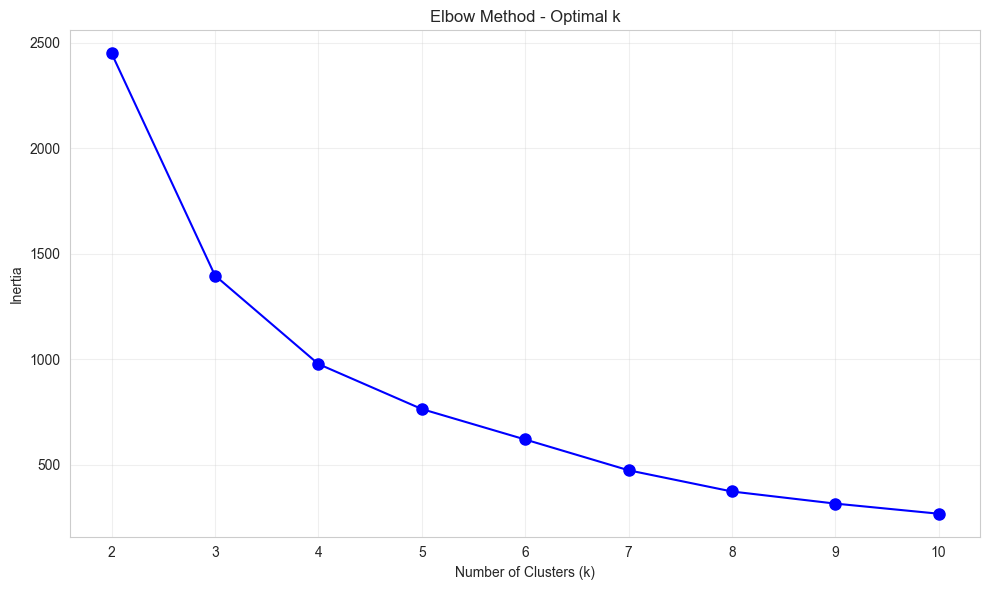

In [5]:
# Plot elbow curve
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(k_range, inertias, 'bo-', markersize=8)
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Inertia')
ax.set_title('Elbow Method - Optimal k')
ax.grid(True, alpha=0.3)
plt.tight_layout()

save_figure(fig, 'kmeans_elbow_curve', output_dir='../outputs/figures')
plt.show()

## Silhouette Scores - Find Optimal K

In [6]:
# Calculate silhouette scores for k=2 to k=10
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)
    print(f"k={k}, Silhouette Score: {score:.4f}")

k=2, Silhouette Score: 0.5075
k=3, Silhouette Score: 0.5135
k=4, Silhouette Score: 0.5428
k=5, Silhouette Score: 0.5781
k=6, Silhouette Score: 0.5840
k=7, Silhouette Score: 0.6257
k=8, Silhouette Score: 0.6876
k=9, Silhouette Score: 0.6950
k=10, Silhouette Score: 0.7378


Saved figure to ../outputs/figures\kmeans_silhouette_scores.png


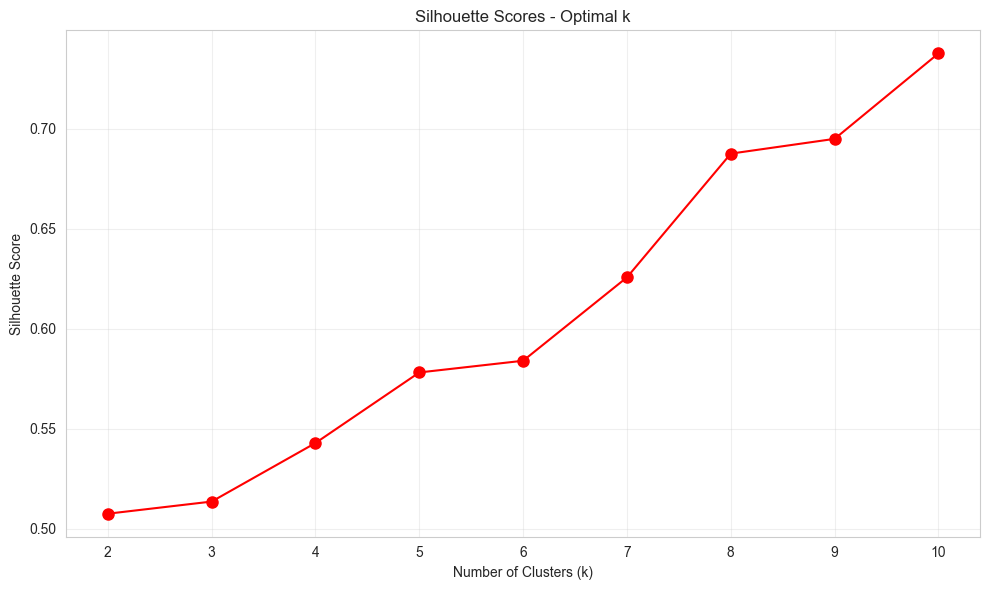

In [7]:
# Plot silhouette scores
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(k_range, silhouette_scores, 'ro-', markersize=8)
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Silhouette Score')
ax.set_title('Silhouette Scores - Optimal k')
ax.grid(True, alpha=0.3)
plt.tight_layout()

save_figure(fig, 'kmeans_silhouette_scores', output_dir='../outputs/figures')
plt.show()

## Fit Final K-Means Model

In [8]:
# Choose optimal k (based on elbow and silhouette analysis)
optimal_k = 3  # Adjust based on the plots above
print(f"Using k={optimal_k} for final clustering")

# Fit final K-Means model
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_scaled)

print(f"\nClustering complete!")
print(f"Inertia: {kmeans_final.inertia_:.2f}")
print(f"Silhouette Score: {silhouette_score(X_scaled, cluster_labels):.4f}")

Using k=3 for final clustering

Clustering complete!
Inertia: 1396.72
Silhouette Score: 0.5135


## Add Cluster Labels to DataFrame

In [9]:
# Add cluster labels to the full dataframe
df['cluster'] = cluster_labels

# Count respondents per cluster
cluster_counts = df['cluster'].value_counts().sort_index()
print("Respondents per cluster:")
print(cluster_counts)
print(f"\nTotal: {cluster_counts.sum()}")

Respondents per cluster:
cluster
0    370
1    700
2    181
Name: count, dtype: int64

Total: 1251


## Profile Each Cluster

In [10]:
# Calculate mean values of clustering features per cluster
cluster_profiles = df.groupby('cluster')[available_features].mean()

print("Cluster Profiles (Mean Values):")
print(cluster_profiles)

Cluster Profiles (Mean Values):
            leave  mental_vs_physical  obs_consequence
cluster                                               
0        2.956757            1.851351              0.0
1        2.065714            0.252857              0.0
2        1.734807            0.850829              1.0


Saved figure to ../outputs/figures\kmeans_cluster_profiles_heatmap.png


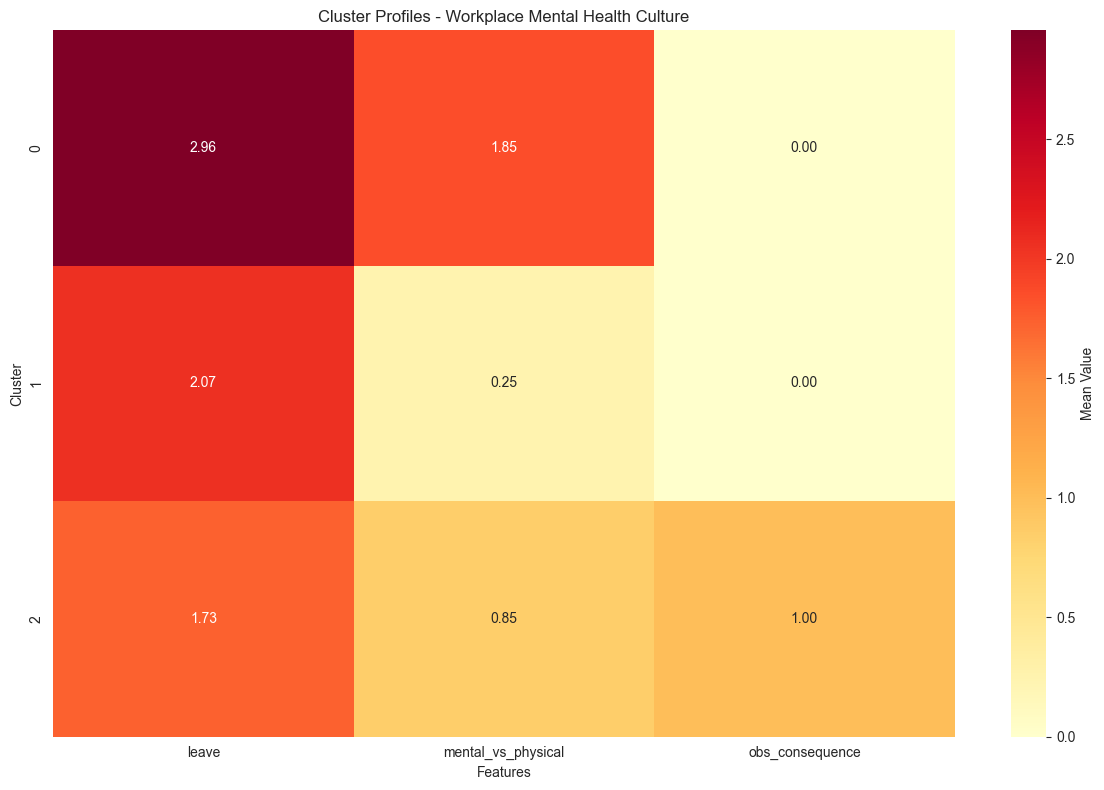

In [11]:
# Plot heatmap of cluster profiles
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(cluster_profiles, annot=True, fmt='.2f', cmap='YlOrRd', 
            cbar_kws={'label': 'Mean Value'}, ax=ax)
ax.set_title('Cluster Profiles - Workplace Mental Health Culture')
ax.set_xlabel('Features')
ax.set_ylabel('Cluster')
plt.tight_layout()

save_figure(fig, 'kmeans_cluster_profiles_heatmap', output_dir='../outputs/figures')
plt.show()

## Treatment-Seeking Rate per Cluster

Treatment-seeking rate per cluster:
Cluster 0: 50.00%
Cluster 1: 46.00%
Cluster 2: 69.06%
Saved figure to ../outputs/figures\kmeans_treatment_by_cluster.png


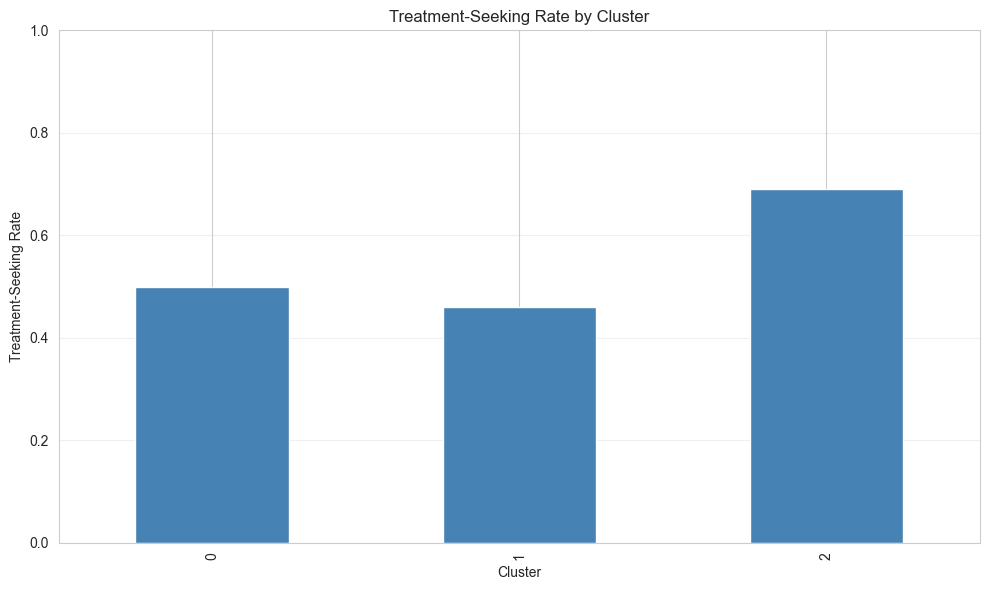

In [12]:
# Calculate treatment-seeking rate per cluster
if 'treatment' in df.columns:
    treatment_by_cluster = df.groupby('cluster')['treatment'].mean()
    
    print("Treatment-seeking rate per cluster:")
    for cluster in sorted(treatment_by_cluster.index):
        rate = treatment_by_cluster[cluster] * 100
        print(f"Cluster {cluster}: {rate:.2f}%")
    
    # Plot treatment-seeking rate per cluster
    fig, ax = plt.subplots(figsize=(10, 6))
    treatment_by_cluster.plot(kind='bar', ax=ax, color='steelblue')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Treatment-Seeking Rate')
    ax.set_title('Treatment-Seeking Rate by Cluster')
    ax.set_ylim([0, 1])
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    
    save_figure(fig, 'kmeans_treatment_by_cluster', output_dir='../outputs/figures')
    plt.show()

## Name Clusters Based on Profiles

In [13]:
# Analyze cluster profiles to assign descriptive names
cluster_names = {}

for cluster in range(optimal_k):
    profile = cluster_profiles.loc[cluster]
    
    # Calculate average score across all features
    avg_score = profile.mean()
    
    # Name based on average support level
    if avg_score >= 0.6:
        cluster_names[cluster] = "Supportive Workplace"
    elif avg_score >= 0.4:
        cluster_names[cluster] = "Moderately Supportive Workplace"
    else:
        cluster_names[cluster] = "Unsupportive Workplace"

print("Cluster Names:")
for cluster, name in cluster_names.items():
    print(f"Cluster {cluster}: {name}")
    print(f"  Average score: {cluster_profiles.loc[cluster].mean():.3f}")
    print(f"  Size: {cluster_counts[cluster]} respondents")

Cluster Names:
Cluster 0: Supportive Workplace
  Average score: 1.603
  Size: 370 respondents
Cluster 1: Supportive Workplace
  Average score: 0.773
  Size: 700 respondents
Cluster 2: Supportive Workplace
  Average score: 1.195
  Size: 181 respondents


## Save Clustered Dataset

In [14]:
# Save clustered dataset
output_path = '../outputs/clustered_survey.csv'
df.to_csv(output_path, index=False)

print(f"Clustered dataset saved to: {output_path}")

Clustered dataset saved to: ../outputs/clustered_survey.csv


## Interpretation

In [15]:
print("="*70)
print("K-MEANS CLUSTERING INTERPRETATION")
print("="*70)
print("\nThe K-Means clustering identified {} distinct workplace mental health".format(optimal_k))
print("culture profiles based on employer-related features:")
print("\nCluster Profiles:")
for cluster in range(optimal_k):
    print(f"\n{cluster_names[cluster]} (Cluster {cluster}):")
    print(f"  - Size: {cluster_counts[cluster]} respondents ({cluster_counts[cluster]/len(df)*100:.1f}%)")
    if 'treatment' in df.columns:
        rate = df.groupby('cluster')['treatment'].mean()[cluster] * 100
        print(f"  - Treatment-seeking rate: {rate:.1f}%")
    print(f"  - Key characteristics:")
    for feature in available_features:
        val = cluster_profiles.loc[cluster, feature]
        print(f"    * {feature}: {val:.3f}")

print("\n" + "="*70)
print("Key Insights:")
print("="*70)
print("- Clusters represent different levels of workplace mental health support.")
print("- Supportive workplaces have higher benefits, care options, and wellness programs.")
print("- Treatment-seeking rates vary across clusters, suggesting workplace")
print("  culture influences employee behavior toward mental health.")
print("- Organizations can use these profiles to assess and improve their")
print("  mental health support systems.")
print("="*70)

K-MEANS CLUSTERING INTERPRETATION

The K-Means clustering identified 3 distinct workplace mental health
culture profiles based on employer-related features:

Cluster Profiles:

Supportive Workplace (Cluster 0):
  - Size: 370 respondents (29.6%)
  - Treatment-seeking rate: 50.0%
  - Key characteristics:
    * leave: 2.957
    * mental_vs_physical: 1.851
    * obs_consequence: 0.000

Supportive Workplace (Cluster 1):
  - Size: 700 respondents (56.0%)
  - Treatment-seeking rate: 46.0%
  - Key characteristics:
    * leave: 2.066
    * mental_vs_physical: 0.253
    * obs_consequence: 0.000

Supportive Workplace (Cluster 2):
  - Size: 181 respondents (14.5%)
  - Treatment-seeking rate: 69.1%
  - Key characteristics:
    * leave: 1.735
    * mental_vs_physical: 0.851
    * obs_consequence: 1.000

Key Insights:
- Clusters represent different levels of workplace mental health support.
- Supportive workplaces have higher benefits, care options, and wellness programs.
- Treatment-seeking rates va